### What are the nulti-Agent RAG Systems ?

A multi-Agent RAG sustem splits pipeline into multiple specialized agents - each responsible for a specific role and enables them to collaborate on a single query or  task

Multi-Agent RAG system with LangGraph

Trasform your documents into seachable knowledge base that can snwer questions intelligently using AI. Simply upload documents and ask questions in natural language- the system finds the relevent information and generates comprehensive answers.

KeyFeatures

1. Multi-format Support : Handles pdf and text documents
2. 3-Agent Architecture : specilized agents for document processing, retrieval and answer Generation.
3. Smart Search : Vecctor-based semantic search finds relevant informtion
4. Natural Langauage Q & A : Ask Questions in plain English

In [124]:
import os
from dotenv import load_dotenv
from langchain.chat_models import init_chat_model

load_dotenv()
os.environ["TAVILY_API_KEY"] = os.getenv("TAVILY_API_KEY")
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [125]:
import truststore
truststore.inject_into_ssl()

In [126]:
llm = init_chat_model("openai:gpt-4o-mini")
llm

ChatOpenAI(metadata={'lc_versions': {'langchain-core': '1.6.6', 'langchain': '1.4.3', 'langchain-openai': '1.6.7'}}, profile={'name': 'GPT-4o mini', 'release_date': '2024-07-18', 'last_updated': '2024-07-18', 'open_weights': False, 'max_input_tokens': 128000, 'max_output_tokens': 16384, 'text_inputs': True, 'image_inputs': True, 'audio_inputs': False, 'pdf_inputs': True, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': False, 'tool_calling': True, 'structured_output': True, 'attachment': True, 'temperature': True, 'image_url_inputs': True, 'pdf_tool_message': True, 'image_tool_message': True, 'tool_choice': True, 'tool_call_streaming': True}, client=<openai.resources.chat.completions.completions.Completions object at 0x000001748047E2C0>, async_client=<openai.resources.chat.completions.completions.AsyncCompletions object at 0x000001748047E650>, root_client=<openai.OpenAI object at 0x000001748047DCD0>

In [127]:
from typing import Annotated

from langchain_tavily import TavilySearch
from langchain_core.tools import tool
from langchain_community.tools import WikipediaQueryRun
from langchain_community.utilities import WikipediaAPIWrapper
from langchain_community.document_loaders import TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_community.vectorstores import FAISS
from langchain_openai import OpenAIEmbeddings

In [128]:
tavily_tool = TavilySearch(max_results= 5)


In [ ]:
from langchain.tools import tool

def make_retrieval_tool_from_text(file, name, desc):
    docs=TextLoader(file, encoding="utf-8").load()
    chunks = RecursiveCharacterTextSplitter(chunk_size=500, chunk_overlap=50).split_documents(docs)
    vs = FAISS.from_documents(chunks, OpenAIEmbeddings())
    retriever = vs.as_retriever()

    def tool_func(query:str) -> str:
        print(f" using tool: {name}")
        results = retriever.invoke(query)
        return "\n".join(doc.page_content for doc in results)

    return Tool(name=name, description=desc, func=tool_func)    

internal_docs_path = os.path.join(os.getcwd(), "internal_docs.txt")
if not os.path.isfile(internal_docs_path):
    with open(internal_docs_path, "w", encoding="utf-8") as file:
        file.write("Add internal research notes here.")

internal_tool_1 = make_retrieval_tool_from_text(
    internal_docs_path,
    "InternalResearchNotes",
    "Search internal research notes for experimental results",
)

internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retrieval_tool_from_text.<locals>.tool_func at 0x00000174825B7E20>)

In [131]:
from langchain_core.messages import BaseMessage, HumanMessage
from langgraph.prebuilt import create_react_agent
from langgraph.graph import MessagesState, END
from langgraph.types import Command

def get_next_node(last_message : BaseMessage, goto : str) :
    if "FINAL ANSWER" in last_message.content:
        return END
    return goto

In [132]:
def make_system_prompt(suffix : str) -> str :
    return (
        "YOu are a helpful AI Assistance, colloborate with other assistants"
        "Use the provided tools to progress towards answering the questions."
        "If you are unable to fully answer, that OK , another assistant with different tools"
        "will help wher you left off. Execute what you can to make progress"
        "if you or any of the other assistants  have the final answer or deliverable"
        "prefix your reponse with FINAL ANSWER so the team knows to stop. \n" + suffix
    )

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\2049704993.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


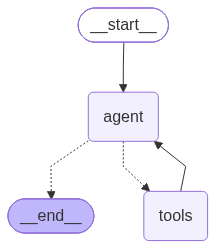

In [134]:
### Research Agent and Node

research_agent = create_react_agent(
    llm,
    tools = [internal_tool_1, tavily_tool],
    prompt = make_system_prompt("You can only do research . Use the tool that are binded with you, you can you both of them. You are working with a content writer colleague"),
)

research_agent

In [136]:
## Research node
from typing import Literal
from langchain_core.messages import HumanMessage
def research_node(state: MessagesState) -> Command[Literal["blog_generator", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # Wrap in a human message, as not all providers allow
    # AI message at the lsat position of the input message list
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(
        update = {"messages" : result["messages"]},
        goto = goto,
    )


In [138]:
###blog write agent

blog_agent = create_react_agent(
    llm,
    tools=[],
    prompt=make_system_prompt(
        "You can only write a detailed blog. You are working wih a researcher colleague."
    )
)


def blog_node (state: MessagesState) -> Command[Literal["researcher", END]]:
    result = research_agent.invoke(state)
    goto = get_next_node(result["messages"][-1], "blog_generator")

    # Wrap in a human message, as not all providers allow
    # AI message at the lsat position of the input message list
    result["messages"][-1] = HumanMessage(content=result["messages"][-1].content, name="researcher")
    return Command(
        update = {"messages" : result["messages"]},
        goto = goto,
    )


C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\1232962732.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  blog_agent = create_react_agent(


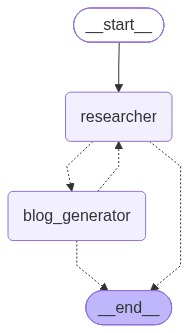

In [139]:
from langgraph.graph import StateGraph, START

workflow = StateGraph(MessagesState)
workflow.add_node('researcher', research_node)
workflow.add_node('blog_generator', blog_node)

workflow.add_edge(START, 'researcher')
graph = workflow.compile()
graph

In [140]:
from langchain_core.messages import HumanMessage

response = graph.invoke({"messages" : "Write a detailed blog on transformer variants in production deployments"})

 using tool: InternalResearchNotes


In [141]:
response["messages"][-1].content

"FINAL ANSWER\n\n### Transformer Variants in Production Deployments: A Comprehensive Overview\n\nThe rise of transformer models has revolutionized natural language processing (NLP), machine learning, and artificial intelligence. As organizations seek to leverage these models in production, understanding the various transformer architectures and deployment strategies becomes essential. This blog aims to elucidate the different variants of transformers utilized in real-world applications, focusing on their advantages, deployment best practices, and the challenges associated with their production use.\n\n#### 1. Understanding Transformer Variants\n\nTransformers are characterized by their self-attention mechanism and ability to handle sequential data more effectively than traditional models. Here are some of the most notable transformer variants:\n\n- **GPT (Generative Pre-trained Transformer)**: Designed for text generation, GPT excels in generating coherent and contextually relevant sen

Supervisor is multi-agent architecture where specialized agents are coordinated by a central supervisor agent. the supervisor agent controls all communication flow and task deletgation , making about agent to invoke based on the current context and Task requirements.

### Multi Agent Supervisor with RAG

In this tutorial, you will build a supervisor system with two agents- a research and math expert, By the end of tutorial you will :

1. Build a specialized research and math agents
2. Build a supervisor for orchestating them witht he prebuilt langgraph-supervisor
3. Build a supervisor 
4. Implement advanced task delegation

In [142]:
internal_tool_1

Tool(name='InternalResearchNotes', description='Search internal research notes for experimental results', func=<function make_retrieval_tool_from_text.<locals>.tool_func at 0x00000174825B7E20>)

In [143]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(max_results=3)
web_search

TavilySearch(max_results=3, api_wrapper=TavilySearchAPIWrapper(tavily_api_key=SecretStr('**********'), api_base_url=None))

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\3508387777.py:3: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  research_agent = create_react_agent(


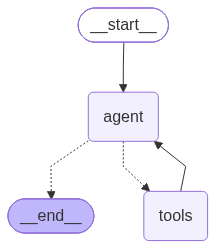

In [144]:
from langgraph.prebuilt import create_react_agent

research_agent = create_react_agent(
    model = llm,
    tools = [web_search, internal_tool_1],
    prompt =  (
        "You are a research agent. \n\n"
        "INSTRUCTIONS: \n"
        "-Assist only with reseach-releated task, DO NOT do any math \n"
        "-After you are done with the your tasks, respond to the supervisor directly\n"
        "-Respond ONLY with the result of your work, do not include any other text."
    ),
    name = "research_agent"
)

research_agent

In [145]:
def add(a: float, b: float) -> float:
    """Return the sum of a and b."""
    return a + b

def subtract(a: float, b: float) -> float:
    """Return the difference of a and b."""
    return a - b    

def multiply(a: float, b: float) -> float:  
    """Return the product of a and b."""
    return a * b    

def divide(a: float, b:float) -> float:
    """Return devision of two numbers """
    return a / b

math_agent = create_react_agent(
    model=llm,
    tools=[add, subtract, multiply, divide],
    prompt=("You are a math agent."
    "INSTRUCTIONS :\n"
    "-Assist only math related tasks\n"
    "-After you are done with your tasks, respond to the supervisor directly.\n"
    "-Respond ONLY with the results of your work, do NOT include any other text.\n"
    ),
    name = "math_agent"
)

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\854176105.py:17: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  math_agent = create_react_agent(


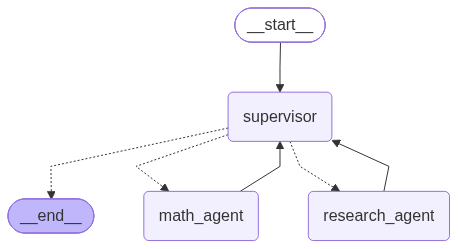

In [146]:
### create supervisor agent

from langgraph_supervisor import create_supervisor


supervisor= create_supervisor(
    model = llm,
    agents=[research_agent, math_agent],
    prompt= ( "You are the supervisor agent managing two agents."
            "INSTRUCTIONS :\n"
            "-a research agent. Assign research related task to this agent\n\n"
            "-a math agent. Assign math-related tasks to this agent \n"
            "-Assign work to one agent at a time, do not call agents in parallel\n"
            "Do not do any work yourself"
            ),
            add_handoff_back_messages = True,
            output_mode= "full_history",
).compile()

supervisor

In [147]:
reponse = supervisor.invoke({"messages": "List all the trasformer variants in production deployments from the retriever and then tell me what is 5 plus 10"})

 using tool: InternalResearchNotes
 using tool: InternalResearchNotes


In [148]:
reponse

{'messages': [HumanMessage(content='List all the trasformer variants in production deployments from the retriever and then tell me what is 5 plus 10', additional_kwargs={}, response_metadata={}, id='c6823c8e-1ac4-4bdd-8e56-621620e522a2'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 13, 'prompt_tokens': 145, 'total_tokens': 158, 'completion_tokens_details': {'accepted_prediction_tokens': 0, 'audio_tokens': 0, 'reasoning_tokens': 0, 'rejected_prediction_tokens': 0, 'text_tokens': None}, 'prompt_tokens_details': {'audio_tokens': 0, 'cache_write_tokens': None, 'cached_tokens': 0, 'image_tokens': None, 'text_tokens': None}}, 'model_provider': 'openai', 'model_name': 'gpt-4o-mini-2024-07-18', 'system_fingerprint': 'fp_d8c31f1e3b', 'id': 'chatcmpl-EZ6tj8uXboMZ51RsgFtETiydfSiMO', 'service_tier': 'default', 'finish_reason': 'tool_calls', 'logprobs': None}, name='supervisor', id='lc_run--01a13db6-042a-7281-879c-6b3316d550e0

### Hierarchial Architecture 

1. Supervisor
2. Research Team - Supervisor - Search , web scrapper
3. Writing Team -  Supervisor - Chart_genertor , doc_writer, note_taker

In [149]:
from typing import Annotated, List
from langchain_community.document_loaders import WebBaseLoader
from langchain_tavily import TavilySearch
from langchain_core.tools import tool

tavily_tool = TavilySearch(max_results=5)


In [150]:
@tool
def scrape_webpages(urls:List[str]) -> str:
    """Use requests and bs4 to scrape the provided web pages for detailed information."""
    loader = WebBaseLoader(urls)
    docs = loader.load()
    return "\n\n".join([
        f'<document name="{doc.metadata.get("title", "")}">\n{doc.page_content}</document>'
        for doc in docs
    ])

In [179]:
from pathlib import Path
from tempfile import TemporaryDirectory

_TEMP_DIRECTORY = TemporaryDirectory()
WORKING_DIRECTORY = Path(_TEMP_DIRECTORY.name)

@tool
def create_outline(
    points : Annotated[List[str], "List of main points or sections"],
    file_name : Annotated[str, "File path to save the outline"],

) -> Annotated[str, "Path to the saved outline file"]:
    """Create and Save an outline."""
    with (WORKING_DIRECTORY / file_name).open("w") as file:
        for i, point in enumerate(points):
            file.write(f"{i+1}. {point}\n")
    return f"outline saved to {file_name}"

@tool
def write_document(
    content:Annotated[str, "Text content to be written into document"],
    file_name: Annotated[str, "File path to save the document"],
) -> Annotated[str, "Path of the saved document file"]:
    """Write content to a document and save it."""
    with (WORKING_DIRECTORY / file_name).open("w") as file:
        file.write(content)
    return f"document saved to {file_name}"

@tool
def edit_document(
    file_name : Annotated[str, "Path of the document to be edited."],
    inserts : Annotated[dict[int, str],
    "Dictionary where key is the line number (1-indexed) and value is the text to be inserted at that line.",
    ],
) -> Annotated[str, "Path of the edited document file"]:
    """Edit the specified document by inserting text at the given line numbers."""
    file_path = WORKING_DIRECTORY / file_name
    with file_path.open("r") as file:
        lines = file.readlines()
    for line_number, text in inserts.items():
        if 1 <= line_number <= len(lines):
            lines.insert(line_number - 1, text + "\n")
        else:
            lines.append(text + "\n")
    with file_path.open("w") as file:
        file.writelines(lines)
    return f"document edited and saved to {file_name}"


In [152]:
from langchain_experimental.utilities import PythonREPL

# Warning : This executes code locally , which can be unsafe when not sandboxed

repl = PythonREPL()

@tool
def phython_repl_tool(
    code : Annotated[str, "Phython code to execute to generate your chart"],
):
    """ Use this to execute phython code. If you want to see the output of a value,
        you should print it out with 'print(...). this is visible to the user."""

    try:
        result = repl.run(code)
    except Exception as e:
        result = f"Failed to execute. Error {repr(e)}"
    return f"Sucessfully executed : \n phython\n {code}\n ...\n Stdout: {result}"

In [164]:
from typing import List, Literal, TypedDict
from langchain_core.language_models import BaseChatModel
from langgraph.graph import END, MessagesState
from langgraph.types import Command

def make_supervisor_node(llm: BaseChatModel, members: List[str]):
    options = ["FINISH"] + members
    system_prompt = (
        "You are a supervisor tasked with managing a conversation between the "
        f"following workers: {members}. Given the following user request,"
        " respond with worker to act next. Each worker will perform a "
        " task and respond with their results and status. When finished."
        " respond with FINISH."
    )

    class Router(TypedDict):
        next: Literal[*options]

    def supervisor_node(state: MessagesState) -> Command[Literal[*members, END]]:
        """An LLM-based router."""
        messages = [{"role": "system", "content": system_prompt}] + state["messages"]
        response = llm.with_structured_output(Router).invoke(messages)
        goto = response["next"]
        if goto == "FINISH":
            goto = END

        return Command(goto=goto, update={"next": goto})

    return supervisor_node

In [157]:
from langchain_core.messages import HumanMessage
from langchain_openai import ChatOpenAI
from langgraph.prebuilt import create_react_agent


search_agent = create_react_agent(llm, tools=[tavily_tool, internal_tool_1])
search_agent

def search_node(state: State) -> Command[Literal["supervisor"]]:
    result = search_agent.invoke(state)
    return Command(
        update = {
            "messages" : [HumanMessage(content=result["messages"][-1].content, name="search")]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor"
    )

### sub agent for web scraping
web_scapper_agent = create_react_agent(llm, tools=[scrape_webpages])

def web_scapper_node(state: State) -> Command[Literal["supervisor"]]:
    result = web_scapper_agent.invoke(state)
    return Command(
        update = {
            "messages" : [HumanMessage(content=result["messages"][-1].content, name="web_scapper")]
        },
        # We want our workers to ALWAYS "report back" to the supervisor when done
        goto="supervisor"
    )

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\2896393931.py:6: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  search_agent = create_react_agent(llm, tools=[tavily_tool, internal_tool_1])
C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\2896393931.py:20: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  web_scapper_agent = create_react_agent(llm, tools=[scrape_webpages])


In [191]:
research_supervisor_node = make_supervisor_node(llm, ["search","web_scapper"])
research_supervisor_node

paper_writing_supervisor_node = make_supervisor_node(llm, ["doc_writer","note_taker","chart_generator"])
paper_writing_supervisor_node

<function __main__.make_supervisor_node.<locals>.supervisor_node(state: langgraph.graph.message.MessagesState) -> langgraph.types.Command[typing.Literal['doc_writer', 'note_taker', 'chart_generator', '__end__']]>

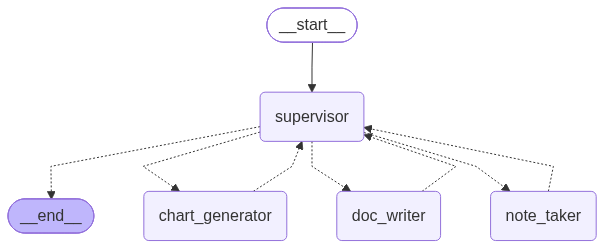

In [192]:
class State(MessagesState):
    next: str

research_builder = StateGraph(State)
research_builder.add_node("supervisor", research_supervisor_node)
research_builder.add_node("search", search_node)
research_builder.add_node("web_scapper", web_scapper_node)

research_builder.add_edge(START, "supervisor")
research_graph = research_builder.compile()
research_graph

paper_writing_builder = StateGraph(State)
paper_writing_builder.add_node("supervisor", paper_writing_supervisor_node)
paper_writing_builder.add_node("doc_writer", doc_writing_node)
paper_writing_builder.add_node("note_taker", note_taking_node)
paper_writing_builder.add_node("chart_generator", chart_gnerating_node)

paper_writing_builder.add_edge(START, "supervisor")
paper_writing_graph = paper_writing_builder.compile()
paper_writing_graph

In [193]:
from typing import Optional

@tool
def read_document(
    file_name : Annotated[str , "File path to read the document from."],
    start : Annotated[Optional[int] , "Starting position to read the document from.Default is 0"] = None,
    end: Annotated[Optional[int], "The endline. Default is None."] = None
) -> str:
    """ Read the specified document """
    with(WORKING_DIRECTORY / file_name).open("r") as file :
        lines = file.readlines()
        if start is None:
            start = 0
        if end is None:
            end = len(lines)
        return "".join(lines[start:end])

In [195]:
doc_writer_agent = create_react_agent(
    llm,
    tools=[write_document, edit_document, read_document],
    prompt=(
        "You can read, write and edit documents based on note-taker's outlines."
        "Don't ask follow-up questions."
    ),
)

def doc_writing_node(state: State)-> Command[Literal["supervisor"]]:
    result = doc_writer_agent.invoke(state)

    return Command(
        update = {
            "messages" : [
                HumanMessage(content=result["messages"][-1].content, name="doc_writer")
            ]
        }
    )

note_taking_agent = create_react_agent(
    llm,
    tools=[create_outline, read_document],
    prompt=(
        "You can read documents and create outline for the document writer."
        "Don't ask follow-up questions."
    ),
)

def note_taking_node(state: State) -> Command[Literal["supervisor"]]:
    result = note_taking_agent.invoke(state)
    return Command(
        update = {
            "messages" : [
                HumanMessage(content=result["messages"][-1].content, name="note_taker")
            ]
        }
    )
    
chart_gnerating_agent = create_react_agent(
    llm,
    tools=[read_document, phython_repl_tool],
    prompt=(
        "You can read documents and generate charts based on the content."
        "Don't ask follow-up questions."
    ),
)

def chart_gnerating_node(state: State) -> Command[Literal["supervisor"]]:
    result = chart_gnerating_agent.invoke(state)
    return Command(
        update = {
            "messages" : [
                HumanMessage(content=result["messages"][-1].content, name="chart_generator")
            ]
        }
    )

doc_writing_supervisor_node = make_supervisor_node(llm, ["doc_writer","note_taker","chart_generator"])

C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\3555787889.py:1: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  doc_writer_agent = create_react_agent(
C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\3555787889.py:21: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  note_taking_agent = create_react_agent(
C:\Users\nmadan\AppData\Local\Temp\ipykernel_41424\3555787889.py:40: LangGraphDeprecatedSinceV10: create_react_agent has been moved to `langchain.agents`. Please update your import to `from langchain.agents import create_agent`. Deprecated in LangGraph V1.0 to be removed in V2.0.
  chart_gnerating_agent = create_react_agent(


In [183]:
from langchain_core.messages import BaseMessage

teams_supervisor_node = make_supervisor_node (llm, ["research_team", "writing_team"])
teams_supervisor_node

<function __main__.make_supervisor_node.<locals>.supervisor_node(state: langgraph.graph.message.MessagesState) -> langgraph.types.Command[typing.Literal['research_team', 'writing_team', '__end__']]>

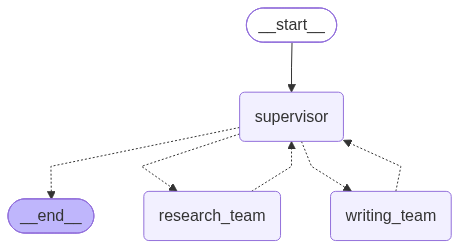

In [196]:
def call_research_team(state: State) -> Command[Literal["supervisor"]]:
    response = research_graph.invoke({"messages" : state["messages"][-1]})
    return Command(update={
        "messages" : [
            HumanMessage(content=response["messages"][-1].content, name="research_team")
            ]
        },
        goto="supervisor"
    )

def call_paper_writing_team(state: State) -> Command[Literal["supervisor"]]:
    response =  paper_writing_graph.invoke({"messages" : state["messages"][-1]})
    return Command(update={
        "messages" : [
            HumanMessage(content=response["messages"][-1].content, name="paper_writing_team")
            ]
        },
        goto="supervisor"
    )

# Define the graph
super_builder = StateGraph(State)
super_builder.add_node("supervisor", teams_supervisor_node)
super_builder.add_node("research_team", call_research_team)
super_builder.add_node("writing_team", call_paper_writing_team)

super_builder.add_edge(START, "supervisor")
super_graph = super_builder.compile()
super_graph

In [197]:
response= super_graph.invoke(
    {
        "messages" : [
        ("user", "Write about trasformer variants in production deployments")
        ],
        
    })

In [198]:
response

{'messages': [HumanMessage(content='Write about trasformer variants in production deployments', additional_kwargs={}, response_metadata={}, id='2efd27ef-8272-4265-a76e-db4e2fddff45'),
  HumanMessage(content='Transformers have revolutionized the field of machine learning, particularly in natural language processing (NLP) and computer vision. With their ability to handle various tasks, several variants of the transformer architecture have been developed and deployed in production environments. Below are some prevalent transformer variants and their applications in real-world settings:\n\n### 1. **BERT (Bidirectional Encoder Representations from Transformers)**\n- **Description**: BERT introduced the concept of pre-training deep bidirectional representations by jointly conditioning on both left and right context in all layers. It uses transformer encoders and is particularly effective for tasks like sentiment analysis, question answering, and named entity recognition.\n- **Production Use*